In [2]:
import pandas as pd

In [64]:
df = pd.read_csv('heart_attack_prediction_dataset.csv')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Patient ID                       8763 non-null   str    
 1   Age                              8763 non-null   int64  
 2   Sex                              8763 non-null   str    
 3   Cholesterol                      8763 non-null   int64  
 4   Blood Pressure                   8763 non-null   str    
 5   Heart Rate                       8763 non-null   int64  
 6   Diabetes                         8763 non-null   int64  
 7   Family History                   8763 non-null   int64  
 8   Smoking                          8763 non-null   int64  
 9   Obesity                          8763 non-null   int64  
 10  Alcohol Consumption              8763 non-null   int64  
 11  Exercise Hours Per Week          8763 non-null   float64
 12  Diet                           

In [5]:
df.head()

,Patient ID,Age,Sex,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Smoking,Obesity,...,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Country,Continent,Hemisphere,Heart Attack Risk
0,BMW7812,67,Male,208,158/88,72,0,0,1,0,...,6.615001,261404,31.251233,286,0,6,Argentina,South America,Southern Hemisphere,0
1,CZE1114,21,Male,389,165/93,98,1,1,1,1,...,4.963459,285768,27.194973,235,1,7,Canada,North America,Northern Hemisphere,0
2,BNI9906,21,Female,324,174/99,72,1,0,0,0,...,9.463426,235282,28.176571,587,4,4,France,Europe,Northern Hemisphere,0
3,JLN3497,84,Male,383,163/100,73,1,1,1,0,...,7.648981,125640,36.464704,378,3,4,Canada,North America,Northern Hemisphere,0
4,GFO8847,66,Male,318,91/88,93,1,1,1,1,...,1.514821,160555,21.809144,231,1,5,Thailand,Asia,Northern Hemisphere,0


In [6]:
df.describe()

,Age,Cholesterol,Heart Rate,Diabetes,Family History,Smoking,Obesity,Alcohol Consumption,Exercise Hours Per Week,Previous Heart Problems,Medication Use,Stress Level,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Heart Attack Risk
count,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000
mean,53.707977,259.877211,75.021682,0.652288,0.492982,0.896839,0.501426,0.598083,10.014284,0.495835,0.498345,5.469702,5.993690,158263.181901,28.891446,417.677051,3.489672,7.023508,0.358211
std,21.249509,80.863276,20.550948,0.476271,0.499979,0.304186,0.500026,0.490313,5.783745,0.500011,0.500026,2.859622,3.466359,80575.190806,6.319181,223.748137,2.282687,1.988473,0.479502
min,18.000000,120.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.002442,0.000000,0.000000,1.000000,0.001263,20062.000000,18.002337,30.000000,0.000000,4.000000,0.000000
25%,35.000000,192.000000,57.000000,0.000000,0.000000,1.000000,0.000000,0.000000,4.981579,0.000000,0.000000,3.000000,2.998794,88310.000000,23.422985,225.500000,2.000000,5.000000,0.000000
50%,54.000000,259.000000,75.000000,1.000000,0.000000,1.000000,1.000000,1.000000,10.069559,0.000000,0.000000,5.000000,5.933622,157866.000000,28.768999,417.000000,3.000000,7.000000,0.000000
75%,72.000000,330.000000,93.000000,1.000000,1.000000,1.000000,1.000000,1.000000,15.050018,1.000000,1.000000,8.000000,9.019124,227749.000000,34.324594,612.000000,5.000000,9.000000,1.000000
max,90.000000,400.000000,110.000000,1.000000,1.000000,1.000000,1.000000,1.000000,19.998709,1.000000,1.000000,10.000000,11.999313,299954.000000,39.997211,800.000000,7.000000,10.000000,1.000000


In [26]:
df.shape

(8763, 26)

In [13]:
import seaborn as sns

<Axes: >

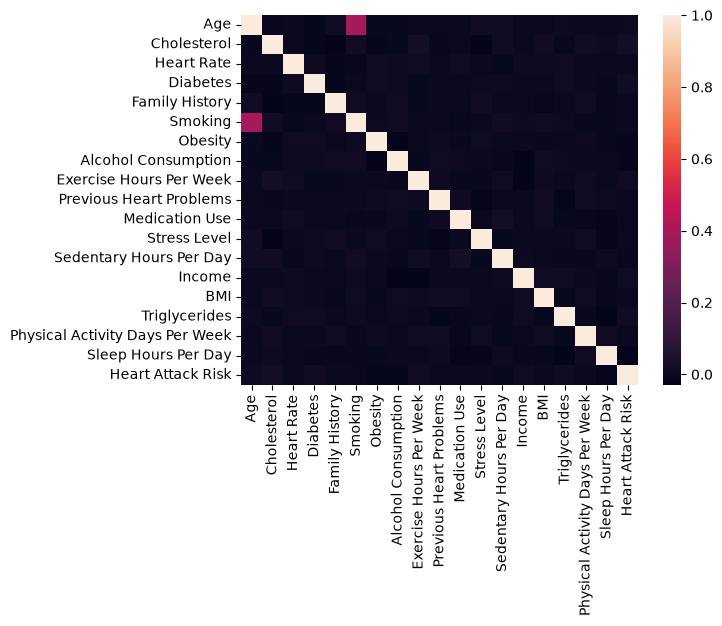

In [14]:
num_cols = df.select_dtypes(include = ['int', 'float'])
cor = num_cols.corr()
sns.heatmap(cor)

<Axes: xlabel='Age', ylabel='Heart Attack Risk'>

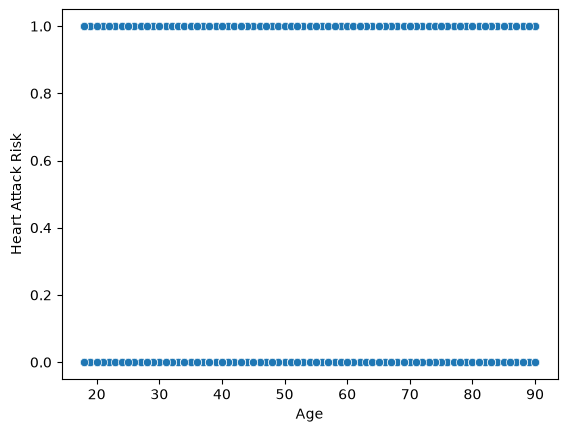

In [17]:
sns.scatterplot(df, x='Age', y = 'Heart Attack Risk')

Возраст не коррелирует с вероятностью сердечного приступа

Судя по heatmap и scatterplot значимых корреляций не выявлено.

In [22]:
import matplotlib.pyplot as plt
import numpy as np


num_cols_lst = num_cols.columns.tolist()

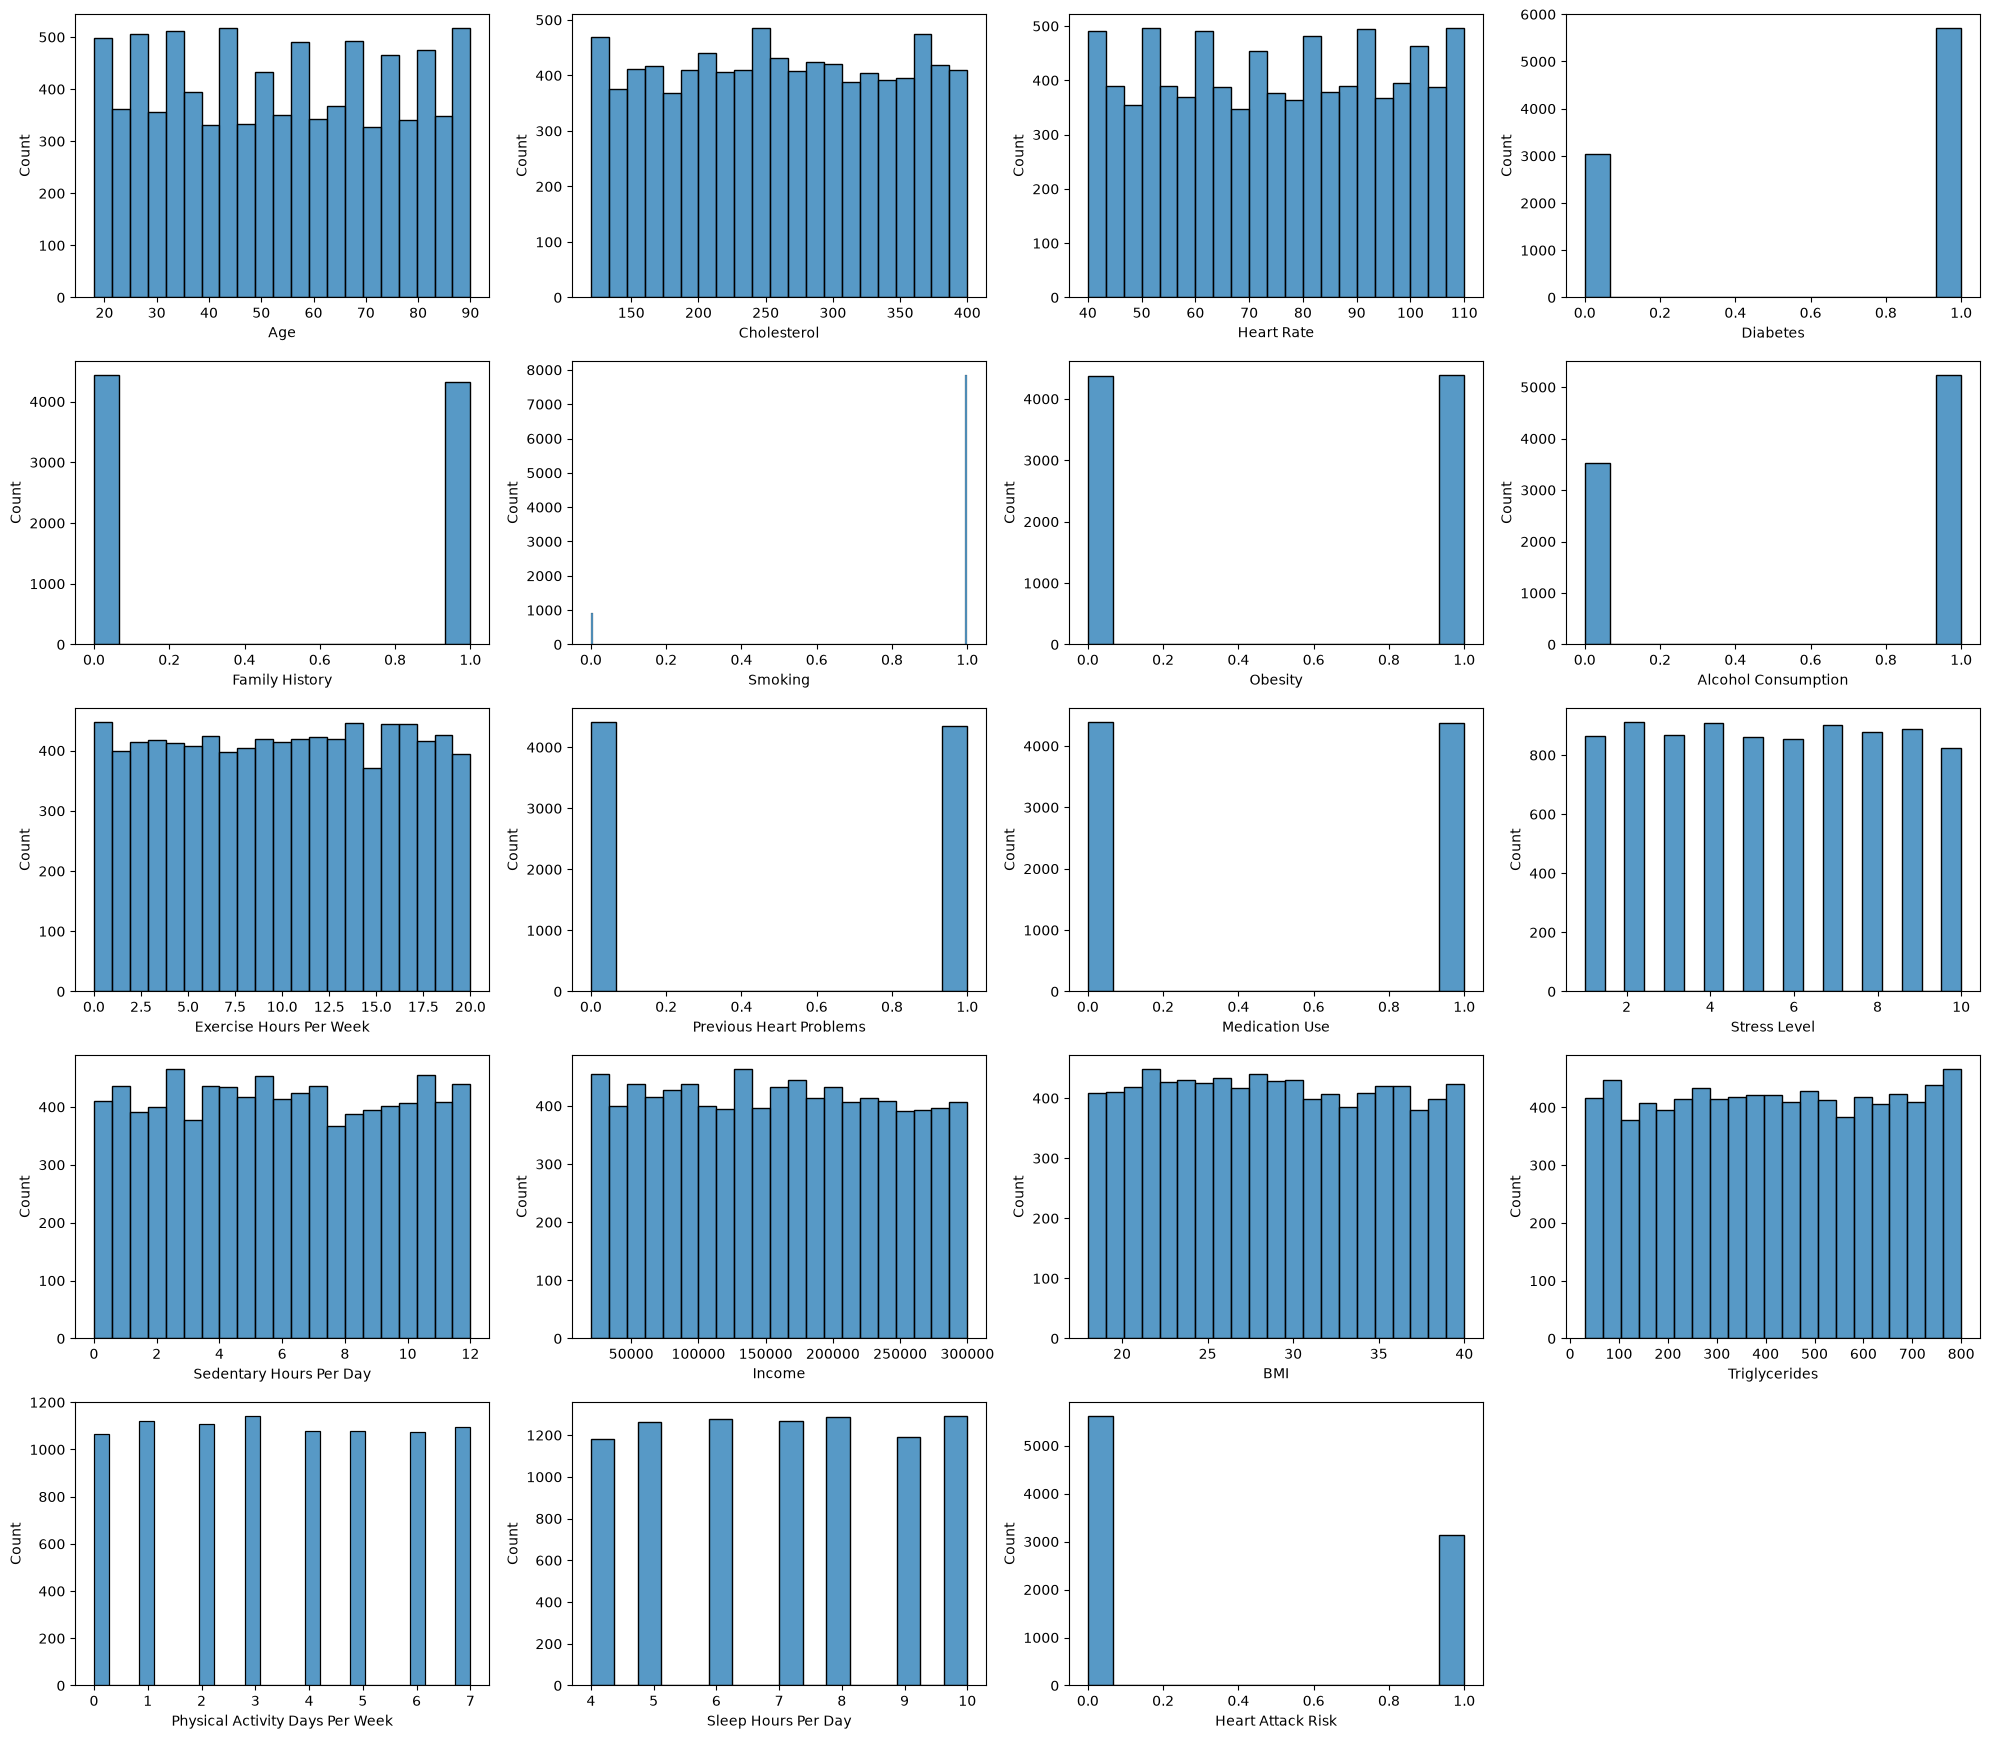

In [31]:
n_cols = 4
n_rows = int(np.ceil(len(num_cols_lst) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize = (20, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(num_cols_lst):
    sns.histplot(df[col].dropna(), ax=axes[i])

for j in range(len(num_cols_lst), len(axes)):
    fig.delaxes(axes[j])
    
plt.tight_layout()
plt.show()


Распределения в датасете двух видов - равномерные и распределения Бернулли, при этом последние делятся еще на сбалансированные, такие как Previos Heart Problems и несбалансированные, такие как Smoking

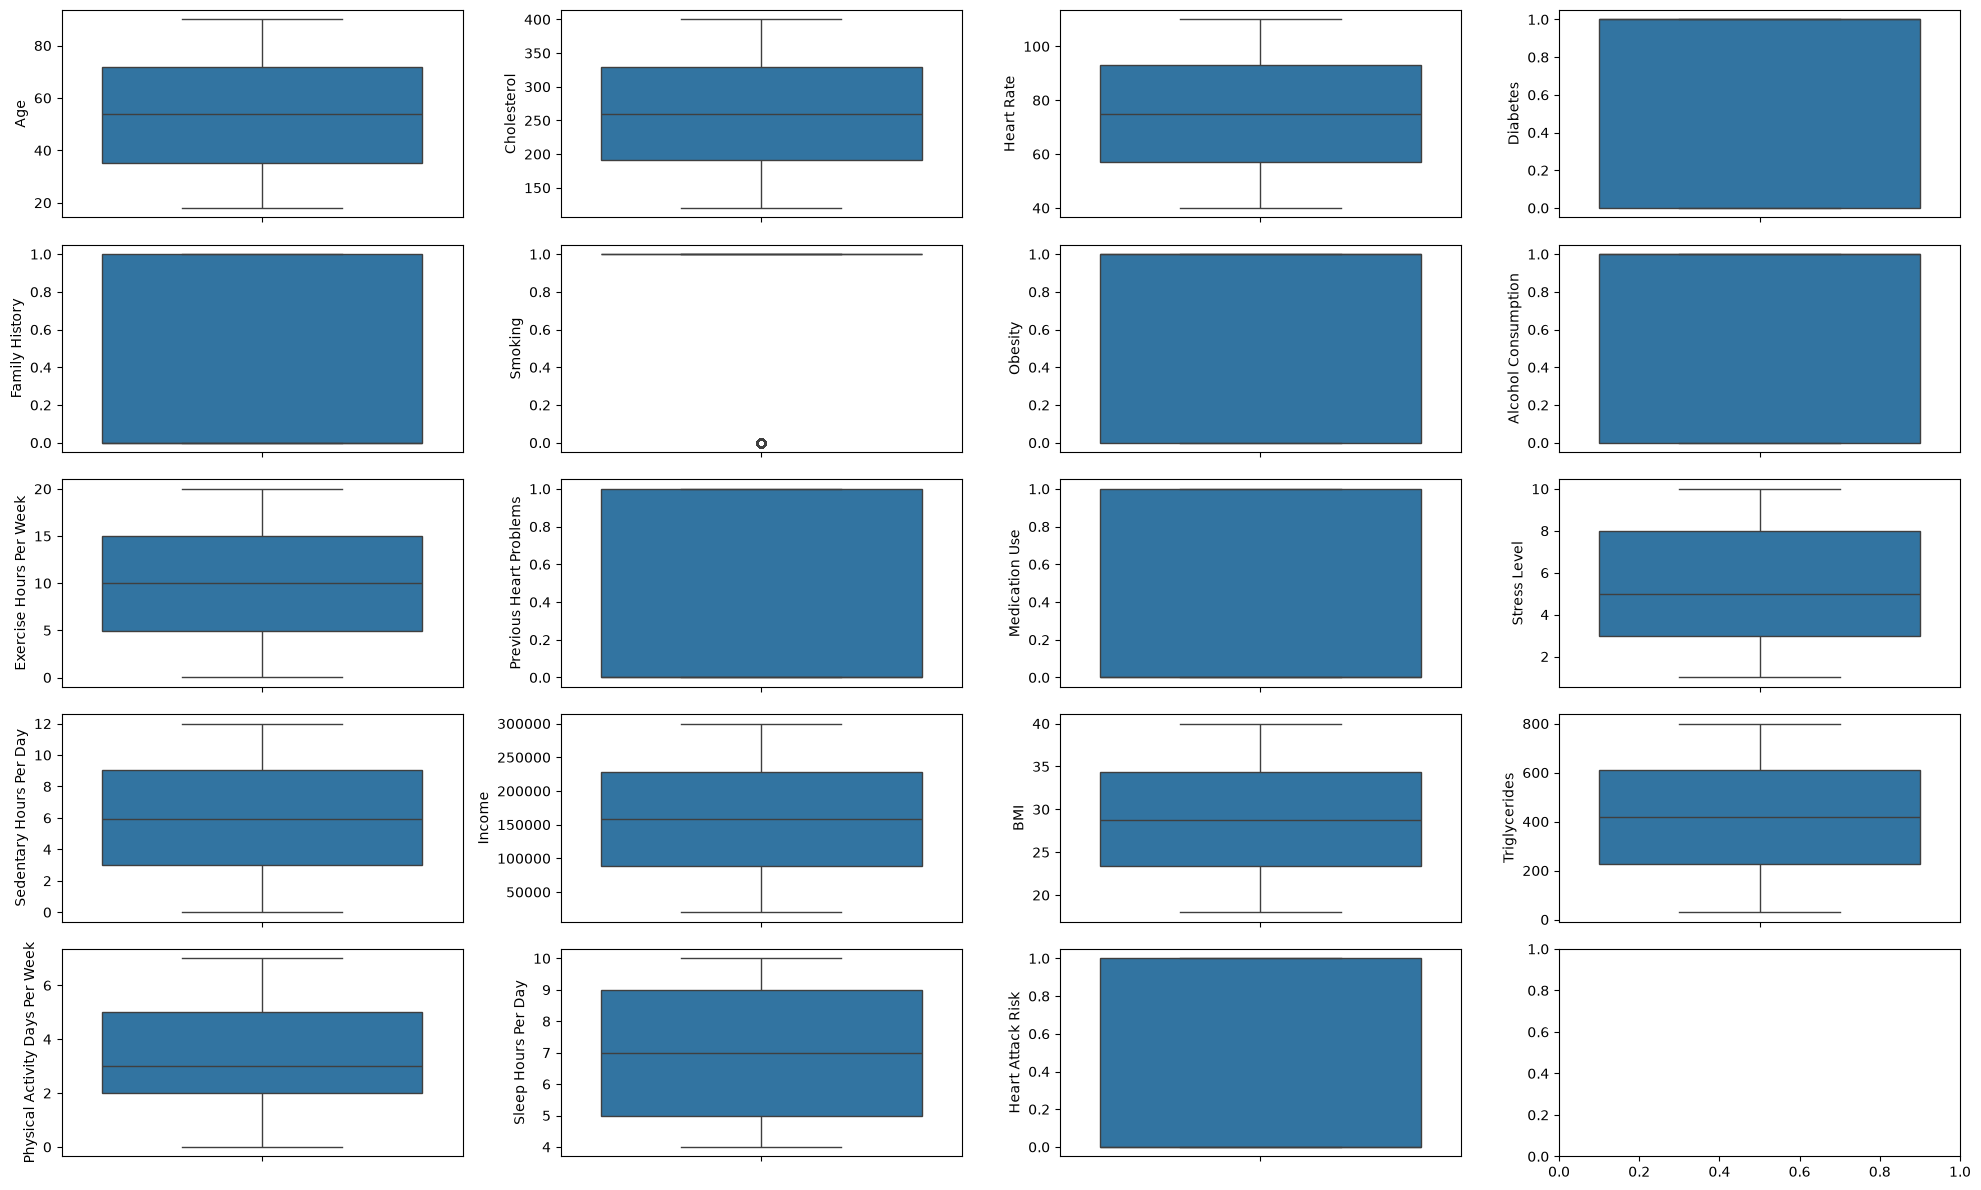

In [42]:
n_cols = 4
n_rows = int(np.ceil(len(num_cols_lst) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize = (20, n_cols * 3))
axes = axes.flatten()

for i, col in enumerate(num_cols_lst):
    sns.boxplot(df[col], ax = axes[i])


plt.tight_layout()
plt.show()

Выбросов не наблюдается. Smoking выглядит "прижатым" к единице, но значения равные 0 выбросами не являются.

В качестве baseline обучим случайный лес. У нас равномерные распределения и слабые корреляции - линейные модели будут работать плохо на этой задаче.

In [ ]:
print(df.columns.tolist())

['Patient ID', 'Age', 'Sex', 'Cholesterol', 'Blood Pressure', 'Heart Rate', 'Diabetes', 'Family History', 'Smoking', 'Obesity', 'Alcohol Consumption', 'Exercise Hours Per Week', 'Diet', 'Previous Heart Problems', 'Medication Use', 'Stress Level', 'Sedentary Hours Per Day', 'Income', 'BMI', 'Triglycerides', 'Physical Activity Days Per Week', 'Sleep Hours Per Day', 'Country', 'Continent', 'Hemisphere', 'Heart Attack Risk']


In [65]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

df = df.dropna()

X = df.drop(columns = ['Heart Attack Risk'])
y = df['Heart Attack Risk']

X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=0.7, random_state = 42)

model = RandomForestClassifier(n_estimators=100)
model.fit(X_train, y_train)


ValueError: could not convert string to float: 'NKL6260'